<a href="https://colab.research.google.com/github/IpanTEKNIKINFORMATIKA/Latihan-Mobile/blob/main/Hands_On_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [6]:
df_mentah = pd.read_csv("case2_customer_churn.csv.csv")

df = df_mentah.copy()

print("Ukuran dataset:", df.shape)

display(df.head())

Ukuran dataset: (5000, 12)


,customer_id,lama_berlangganan_bulan,jenis_kontrak,tagihan_bulanan_idr,total_tagihan_idr,layanan_internet,jumlah_layanan_aktif,dukungan_teknis,jumlah_komplain,hari_sejak_interaksi_terakhir,metode_pembayaran,status_pelanggan
0,TEL000001,41.0,Dua Tahun,140611.0,5860742.0,DSL,8.0,Tidak,11.0,331.0,Transfer Bank,Aktif
1,TEL000002,5.0,Tahunan,363720.0,1742224.0,Tidak Ada,7.0,Ya,12.0,156.0,Autodebet,Aktif
2,TEL000003,56.0,Bulanan,208727.0,11685438.0,DSL,6.0,Tidak,9.0,105.0,Transfer Bank,Churn
3,TEL000004,NaN,Dua Tahun,135607.0,5599065.0,Fiber Optik,2.0,Ya,12.0,100.0,Kartu Kredit,Churn
4,TEL000005,7.0,Bulanan,71099.0,427199.0,Tidak Ada,1.0,Tidak,1.0,19.0,QRIS,Churn


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    5000 non-null   object 
 1   lama_berlangganan_bulan        4900 non-null   float64
 2   jenis_kontrak                  4853 non-null   object 
 3   tagihan_bulanan_idr            4857 non-null   float64
 4   total_tagihan_idr              4763 non-null   float64
 5   layanan_internet               4844 non-null   object 
 6   jumlah_layanan_aktif           4819 non-null   float64
 7   dukungan_teknis                4852 non-null   object 
 8   jumlah_komplain                4836 non-null   float64
 9   hari_sejak_interaksi_terakhir  4797 non-null   float64
 10  metode_pembayaran              4841 non-null   object 
 11  status_pelanggan               5000 non-null   object 
dtypes: float64(6), object(6)
memory usage: 468.9+ KB

In [5]:
df.describe(include="all")

,customer_id,lama_berlangganan_bulan,jenis_kontrak,tagihan_bulanan_idr,total_tagihan_idr,layanan_internet,jumlah_layanan_aktif,dukungan_teknis,jumlah_komplain,hari_sejak_interaksi_terakhir,metode_pembayaran,status_pelanggan
count,5000,4900.000000,4853,4857.000000,4.763000e+03,4844,4819.000000,4852,4836.000000,4797.000000,4841,5000
unique,5000,NaN,12,NaN,NaN,3,NaN,2,NaN,NaN,4,2
top,TEL000001,NaN,Dua Tahun,NaN,NaN,Tidak Ada,NaN,Ya,NaN,NaN,QRIS,Aktif
freq,1,NaN,1623,NaN,NaN,1637,NaN,2489,NaN,NaN,1262,2819
mean,NaN,36.624082,NaN,273390.505250,9.962093e+06,NaN,4.528740,NaN,7.482837,182.542631,NaN,NaN
std,NaN,21.056159,NaN,130685.216371,7.951489e+06,NaN,2.282951,NaN,4.672071,105.117812,NaN,NaN
min,NaN,1.000000,NaN,50245.000000,0.000000e+00,NaN,1.000000,NaN,0.000000,0.000000,NaN,NaN
25%,NaN,18.000000,NaN,160098.000000,3.503040e+06,NaN,3.000000,NaN,3.000000,93.000000,NaN,NaN
50%,NaN,36.000000,NaN,272473.000000,7.873608e+06,NaN,5.000000,NaN,8.000000,183.000000,NaN,NaN
75%,NaN,55.000000,NaN,388440.000000,1.464650e+07,NaN,7.000000,NaN,12.000000,272.000000,NaN,NaN


In [7]:
print("Jumlah duplikat:")
print(df.duplicated().sum())

print("\nMissing value:")
print(df.isnull().sum())

print("\nTipe data:")
print(df.dtypes)

Jumlah duplikat:
0

Missing value:
customer_id                        0
lama_berlangganan_bulan          100
jenis_kontrak                    147
tagihan_bulanan_idr              143
total_tagihan_idr                237
layanan_internet                 156
jumlah_layanan_aktif             181
dukungan_teknis                  148
jumlah_komplain                  164
hari_sejak_interaksi_terakhir    203
metode_pembayaran                159
status_pelanggan                   0
dtype: int64

Tipe data:
customer_id                       object
lama_berlangganan_bulan          float64
jenis_kontrak                     object
tagihan_bulanan_idr              float64
total_tagihan_idr                float64
layanan_internet                  object
jumlah_layanan_aktif             float64
dukungan_teknis                   object
jumlah_komplain                  float64
hari_sejak_interaksi_terakhir    float64
metode_pembayaran                 object
status_pelanggan                  object
dtyp

In [8]:
jumlah_awal = len(df)

df = df.drop_duplicates()

print("Data duplikat dihapus:", jumlah_awal - len(df))
print("Jumlah data sekarang:", len(df))

Data duplikat dihapus: 0
Jumlah data sekarang: 5000


In [9]:
kolom_num = df.select_dtypes(include=np.number).columns
kolom_kat = df.select_dtypes(include="object").columns

for kolom in kolom_num:
    df[kolom] = df[kolom].fillna(df[kolom].median())

for kolom in kolom_kat:
    if df[kolom].isnull().any():
        df[kolom] = df[kolom].fillna(df[kolom].mode()[0])

print(df.isnull().sum())

customer_id                      0
lama_berlangganan_bulan          0
jenis_kontrak                    0
tagihan_bulanan_idr              0
total_tagihan_idr                0
layanan_internet                 0
jumlah_layanan_aktif             0
dukungan_teknis                  0
jumlah_komplain                  0
hari_sejak_interaksi_terakhir    0
metode_pembayaran                0
status_pelanggan                 0
dtype: int64


In [11]:
for kolom in kolom_num:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    df[kolom] = df[kolom].clip(
        lower=batas_bawah,
        upper=batas_atas
    )

print("Penanganan outlier selesai.")

Penanganan outlier selesai.


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    5000 non-null   object 
 1   lama_berlangganan_bulan        5000 non-null   float64
 2   jenis_kontrak                  5000 non-null   object 
 3   tagihan_bulanan_idr            5000 non-null   float64
 4   total_tagihan_idr              5000 non-null   float64
 5   layanan_internet               5000 non-null   object 
 6   jumlah_layanan_aktif           5000 non-null   float64
 7   dukungan_teknis                5000 non-null   object 
 8   jumlah_komplain                5000 non-null   float64
 9   hari_sejak_interaksi_terakhir  5000 non-null   float64
 10  metode_pembayaran              5000 non-null   object 
 11  status_pelanggan               5000 non-null   object 
dtypes: float64(6), object(6)
memory usage: 468.9+ KB

In [13]:
def cek_kualitas(d, kolom_num):
    outlier_total = 0

    for kolom in kolom_num:
        q1 = d[kolom].quantile(0.25)
        q3 = d[kolom].quantile(0.75)
        iqr = q3 - q1

        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr

        outlier_total += (
            (d[kolom] < batas_bawah) |
            (d[kolom] > batas_atas)
        ).sum()

    return {
        "jumlah_baris": len(d),
        "duplikat": d.duplicated().sum(),
        "missing_value": d.isnull().sum().sum(),
        "outlier": outlier_total
    }

laporan = pd.DataFrame({
    "Sebelum": cek_kualitas(df_mentah,
        df_mentah.select_dtypes(include=np.number).columns),
    "Sesudah": cek_kualitas(df,
        df.select_dtypes(include=np.number).columns)
})

display(laporan)

,Sebelum,Sesudah
jumlah_baris,5000,5000
duplikat,0,0
missing_value,1638,0
outlier,59,0


In [15]:
# Menggunakan nama kolom target yang benar yaitu 'status_pelanggan'
df["status_pelanggan"].value_counts()

,count
status_pelanggan,
Aktif,2819
Churn,2181


In [17]:
df["status_pelanggan"].value_counts(normalize=True) * 100

,proportion
status_pelanggan,
Aktif,56.38
Churn,43.62


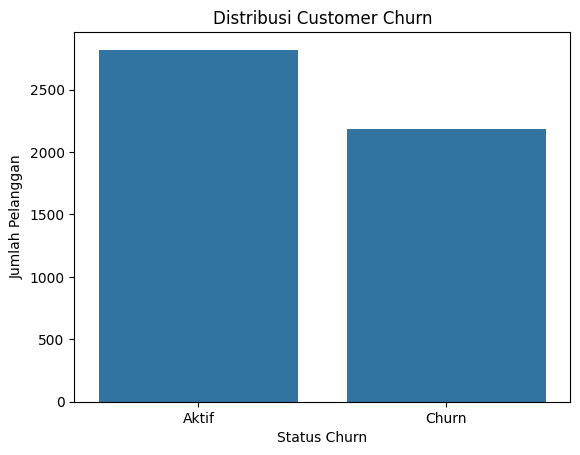

In [19]:
sns.countplot(data=df, x="status_pelanggan")

plt.title("Distribusi Customer Churn")
plt.xlabel("Status Churn")
plt.ylabel("Jumlah Pelanggan")
plt.show()